<a href="https://colab.research.google.com/github/diptanud023/Heart-disease-prediction/blob/main/notebooks/heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
print(os.listdir())


['.config', 'drive', 'sample_data']


In [6]:
df = pd.read_csv("/heart_disease_uci.csv")
print(df.shape)

(920, 16)


In [7]:
print(df.columns.tolist())
print(df['dataset'].value_counts())
print(df['num'].value_counts())
print(df.isna().mean().round(2))
print("duplicates:", df.duplicated().sum())
print("chol == 0:", (df['chol'] == 0).sum())
print("trestbps == 0:", (df['trestbps'] == 0).sum())

['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64
id          0.00
age         0.00
sex         0.00
dataset     0.00
cp          0.00
trestbps    0.06
chol        0.03
fbs         0.10
restecg     0.00
thalch      0.06
exang       0.06
oldpeak     0.07
slope       0.34
ca          0.66
thal        0.53
num         0.00
dtype: float64
duplicates: 0
chol == 0: 172
trestbps == 0: 1


In [8]:
df = df.drop(columns=["id"]).drop_duplicates()
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns=["num"])

for c in ["chol", "trestbps"]:
    df.loc[df[c] == 0, c] = np.nan

print(df.shape)
print(df["target"].value_counts())
print(df.groupby("dataset")["chol"].apply(lambda s: s.isna().mean()).round(2))

(918, 15)
target
1    508
0    410
Name: count, dtype: int64
dataset
Cleveland        0.00
Hungary          0.08
Switzerland      1.00
VA Long Beach    0.28
Name: chol, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

X = df.drop(columns=["target", "dataset", "ca", "thal"])
y = df["target"]

cat_cols = [c for c in X.columns if X[c].dtype == "object" or X[c].dtype == "bool"]
X[cat_cols] = X[cat_cols].astype(str)
num_cols = [c for c in X.columns if c not in cat_cols]
print("categorical:", cat_cols)
print("numeric:", num_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             eval_metric="logloss", random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["recall", "precision", "roc_auc"])
    print(name, {k: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in s.items() if k.startswith("test")})

categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']
numeric: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Logistic Regression {'test_recall': '0.855 ± 0.020', 'test_precision': '0.817 ± 0.048', 'test_roc_auc': '0.878 ± 0.049'}
Random Forest {'test_recall': '0.857 ± 0.025', 'test_precision': '0.818 ± 0.056', 'test_roc_auc': '0.869 ± 0.050'}
XGBoost {'test_recall': '0.840 ± 0.011', 'test_precision': '0.817 ± 0.047', 'test_roc_auc': '0.864 ± 0.049'}


In [11]:
mask = df["dataset"] != "Switzerland"
X2, y2 = X[mask], y[mask]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, stratify=y2, random_state=42)

for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    s = cross_validate(pipe, X2_train, y2_train, cv=cv,
                       scoring=["recall", "precision", "roc_auc"])
    print(name, {k: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in s.items() if k.startswith("test")})

Logistic Regression {'test_recall': '0.803 ± 0.058', 'test_precision': '0.793 ± 0.071', 'test_roc_auc': '0.874 ± 0.048'}
Random Forest {'test_recall': '0.793 ± 0.056', 'test_precision': '0.792 ± 0.047', 'test_roc_auc': '0.865 ± 0.050'}
XGBoost {'test_recall': '0.787 ± 0.057', 'test_precision': '0.771 ± 0.036', 'test_roc_auc': '0.858 ± 0.043'}


              precision    recall  f1-score   support

  no disease       0.84      0.78      0.81        82
     disease       0.83      0.88      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



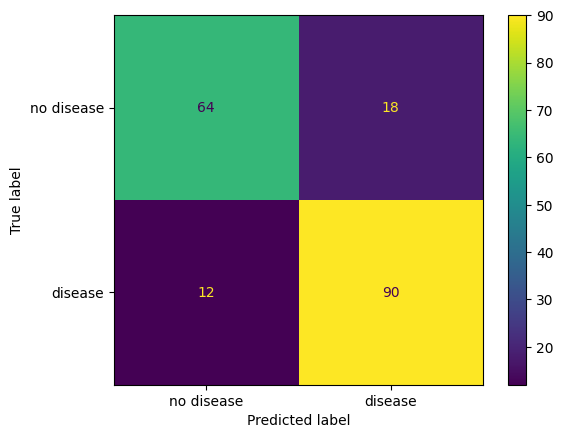

In [12]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best = Pipeline([("pre", pre), ("model", models["Logistic Regression"])])
best.fit(X_train, y_train)
pred = best.predict(X_test)

print(classification_report(y_test, pred, target_names=["no disease", "disease"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["no disease", "disease"])
plt.show()

threshold: 0.41
              precision    recall  f1-score   support

  no disease       0.88      0.71      0.78        82
     disease       0.80      0.92      0.85       102

    accuracy                           0.83       184
   macro avg       0.84      0.81      0.82       184
weighted avg       0.83      0.83      0.82       184



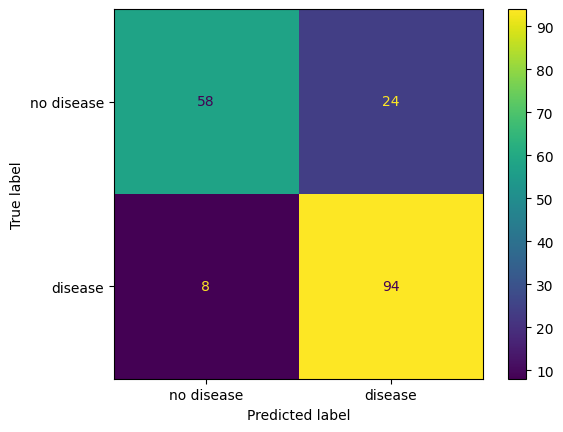

In [15]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

proba = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(y_train, proba)
thr = t[np.where(r[:-1] >= 0.90)[0].max()]
print("threshold:", round(thr, 3))

test_pred = (best.predict_proba(X_test)[:, 1] >= thr).astype(int)
print(classification_report(y_test, test_pred, target_names=["no disease", "disease"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["no disease", "disease"])
plt.savefig("confusion_matrix_tuned.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import joblib, sklearn, xgboost
options = {c: sorted(X[c].unique().tolist()) for c in cat_cols}
joblib.dump({"model": best, "threshold": float(thr), "columns": list(X.columns), "options": options}, "model.joblib")
print(options)
print("scikit-learn", sklearn.__version__)

{'sex': ['Female', 'Male'], 'cp': ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina'], 'fbs': ['False', 'True', 'nan'], 'restecg': ['lv hypertrophy', 'nan', 'normal', 'st-t abnormality'], 'exang': ['False', 'True', 'nan'], 'slope': ['downsloping', 'flat', 'nan', 'upsloping']}
scikit-learn 1.6.1
